## Stage 3: Model Selection and Governance:

### Objective
We will compare the Logistic Regression baseline with a Decision Tree model built in this notebook optimised using Optuna.

Thereby goal is to improve the identification of potentially high-risk insurance policies while balancing claim detection, false positives and interpretability.

### Modelling Workflow
1. Load the baseline model
2. Tune Decision Tree hyperparameters using Optuna.
3. Compare models using cross-validation.
4. Evaluate the selected model on the held-out test set.
5. Track experiments using MLflow.
6. Save the selected model and version metadata.
7. Generate a data or model quality report using Evidently.
8. Explain influential features using SHAP.

### Evaluation Metrics
Accuracy, Precision, Recall, F1 Score and ROC-AUC.

### Model Selection Principle
The final model will be selected based on validation performance and business usefulness, not accuracy alone.

In [1]:
import sys

print(sys.executable)

d:\UPGRAD\.venv\Scripts\python.exe


In [2]:
import importlib

packages = [
    "optuna",
    "mlflow",
    "shap",
    "evidently",
    "joblib"
]

for package in packages:
    try:
        importlib.import_module(package)
        print(f"{package} ✅ Installed")
    except:
        print(f"{package} ❌ Not Installed")

optuna ✅ Installed
mlflow ✅ Installed
shap ✅ Installed
evidently ✅ Installed
joblib ✅ Installed


#### 1.1 Importing important Libraries

In [3]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import optuna
import mlflow
import mlflow.sklearn
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TARGET = "is_claim"

print("Stage 3 libraries imported successfully.")

Stage 3 libraries imported successfully.


#### 1.2. Load the Stage 1 Dataset

In [4]:
# Load the Stage 1 cleaned and feature-engineered dataset.
# Keep the CSV in the same folder as this notebook, or update DATA_PATH.

DATA_PATH = r"D:\UPGRAD\CapStone_Project\insurance_stage1_cleaned.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

print("\nTarget distribution:")
display(df["is_claim"].value_counts(dropna=False))


Dataset shape: (58592, 49)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,max_power_bhp,max_torque_nm,safety_equipment_count,power_to_weight,High_Risk_Driver_Flag
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,0,0,1,0,0,40.36,60.0,3,0.034059,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,0,0,1,0,0,40.36,60.0,3,0.034059,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,0,0,1,0,0,40.36,60.0,3,0.034059,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,1,1,1,2,0,88.50,113.0,14,0.066292,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,1,1,1,2,0,67.06,91.0,7,0.058061,0



Target distribution:


is_claim
0    54844
1     3748
Name: count, dtype: int64

#### 1.3. Separating Predictors and Target:

In [5]:
# Separate predictors and target
TARGET = "is_claim"

X = df.drop(
    columns=[TARGET, "policy_id", "max_power", "max_torque"],
    errors="ignore"
)
y = pd.to_numeric(df[TARGET], errors="raise").astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique()))

assert set(y.unique()).issubset({0, 1}), "Target must contain only 0 and 1."


Predictor shape: (58592, 45)
Target shape: (58592,)
Target values: [np.int64(0), np.int64(1)]


#### 1.4. Train-Test Split:
Creating a 80/20 stratified split using the same random state as Stage 2.
The training set will be used for cross-validation and Optuna tuning. The test set will remain untouched until the final evaluation.

Using the same split strategy allows us to compare the models fairly while reducing the risk of test-set leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

print("\nTrain Claim Rate:",
      round(y_train.mean() * 100, 2), "%")

print("Test Claim Rate:",
      round(y_test.mean() * 100, 2), "%")

Train Shape: (46873, 45)
Test Shape: (11719, 45)

Train Claim Rate: 6.4 %
Test Claim Rate: 6.4 %


#### Using Featuretools to automate feature engineering for model building

In [7]:
import featuretools as ft

print("Featuretools version:", ft.__version__)

Featuretools version: 1.31.0


In [8]:
# Featuretools: Deep Feature Synthesis
import featuretools as ft

TARGET = "is_claim"
ID_COL = "policy_id"

# Generate features only from predictors that are actually in X.
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# Keep the unique policy ID for Featuretools alignment.
df_ft = df[[ID_COL] + numeric_features].copy()

assert df_ft[ID_COL].is_unique, (
    "policy_id must be unique for Featuretools alignment."
)

entity_set = ft.EntitySet(id="insurance_data")

entity_set = entity_set.add_dataframe(
    dataframe_name="policies",
    dataframe=df_ft,
    index=ID_COL
)

feature_matrix, feature_defs = ft.dfs(
    entityset=entity_set,
    target_dataframe_name="policies",
    trans_primitives=["add_numeric", "multiply_numeric"],
    max_depth=1
)

dfs_features = [
    col for col in feature_matrix.columns
    if col not in df_ft.columns
]

print("Base numeric features:", len(numeric_features))
print("Generated DFS features:", len(dfs_features))
display(feature_matrix[dfs_features].head())


Base numeric features: 37
Generated DFS features: 1332


,High_Risk_Driver_Flag + is_adjustable_steering,High_Risk_Driver_Flag + is_brake_assist,High_Risk_Driver_Flag + is_central_locking,High_Risk_Driver_Flag + is_day_night_rear_view_mirror,High_Risk_Driver_Flag + is_driver_seat_height_adjustable,High_Risk_Driver_Flag + is_ecw,High_Risk_Driver_Flag + is_esc,High_Risk_Driver_Flag + is_front_fog_lights,High_Risk_Driver_Flag + is_parking_camera,High_Risk_Driver_Flag + is_parking_sensors,...,population_density * power_to_weight,population_density * safety_equipment_count,population_density * turning_radius,population_density * width,power_to_weight * safety_equipment_count,power_to_weight * turning_radius,power_to_weight * width,safety_equipment_count * turning_radius,safety_equipment_count * width,turning_radius * width
policy_id,,,,,,,,,,,,,,,,,,,,,
ID00001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,169.954768,14970.0,22954.0,7559850.0,0.102177,0.156672,51.599494,13.8,4545.0,6969.0
ID00002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,919.697114,81009.0,124213.8,40909545.0,0.102177,0.156672,51.599494,13.8,4545.0,6969.0
ID00003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,138.824776,12228.0,18749.6,6175140.0,0.102177,0.156672,51.599494,13.8,4545.0,6969.0
ID00004,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1433.368539,302708.0,103785.6,37514170.0,0.928090,0.318202,115.016854,67.2,24290.0,8328.0
ID00005,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,2016.909333,243166.0,173690.0,54851302.0,0.406424,0.290303,91.677697,35.0,11053.0,7895.0


In [9]:
train_policy_ids = df.loc[
    X_train.index,
    "policy_id"
].tolist()

In [10]:
print("Number of DFS Features:", len(dfs_features))
print(dfs_features[:10])

Number of DFS Features: 1332
['High_Risk_Driver_Flag + is_adjustable_steering', 'High_Risk_Driver_Flag + is_brake_assist', 'High_Risk_Driver_Flag + is_central_locking', 'High_Risk_Driver_Flag + is_day_night_rear_view_mirror', 'High_Risk_Driver_Flag + is_driver_seat_height_adjustable', 'High_Risk_Driver_Flag + is_ecw', 'High_Risk_Driver_Flag + is_esc', 'High_Risk_Driver_Flag + is_front_fog_lights', 'High_Risk_Driver_Flag + is_parking_camera', 'High_Risk_Driver_Flag + is_parking_sensors']


In [11]:
base_corr = (
    X_train[numeric_features]
    .corrwith(y_train)
    .abs()
    .sort_values(ascending=False)
)

display(base_corr.head(10))

best_base_corr = base_corr.max()

print(
    "Strongest Base Feature Correlation:",
    round(best_base_corr, 5)
)

policy_tenure                       0.082656
age_of_car                          0.027402
age_of_policyholder                 0.021923
population_density                  0.019806
High_Risk_Driver_Flag               0.015573
cylinder                            0.013611
is_adjustable_steering              0.013557
is_front_fog_lights                 0.010951
is_brake_assist                     0.010691
is_driver_seat_height_adjustable    0.009936
dtype: float64

Strongest Base Feature Correlation: 0.08266


In [12]:
base_corr.sort_values(
    ascending=False
).head(10)

policy_tenure                       0.082656
age_of_car                          0.027402
age_of_policyholder                 0.021923
population_density                  0.019806
High_Risk_Driver_Flag               0.015573
cylinder                            0.013611
is_adjustable_steering              0.013557
is_front_fog_lights                 0.010951
is_brake_assist                     0.010691
is_driver_seat_height_adjustable    0.009936
dtype: float64

In [13]:
# Score DFS features using training rows only

train_policy_ids = df.loc[X_train.index, ID_COL].tolist()
y_train_corr = y_train.loc[X_train.index].reset_index(drop=True)

dfs_corr = {}

for feature in dfs_features:
    feature_values = (
        feature_matrix.loc[train_policy_ids, feature]
        .reset_index(drop=True)
    )

    feature_values = pd.to_numeric(
        feature_values, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    # Impute for this correlation screen only.
    if feature_values.notna().any():
        feature_values = feature_values.fillna(
            feature_values.median()
        )
        corr = feature_values.corr(y_train_corr)
    else:
        corr = np.nan

    dfs_corr[feature] = (
        abs(float(corr)) if pd.notna(corr) else 0.0
    )

dfs_corr_table = pd.DataFrame({
    "Feature": list(dfs_corr.keys()),
    "Absolute_Correlation": list(dfs_corr.values())
}).sort_values(
    "Absolute_Correlation", ascending=False
).reset_index(drop=True)

# Compare against the strongest numeric feature actually used by X.
base_numeric_train = X_train[numeric_features].copy()

base_corr = (
    base_numeric_train
    .corrwith(y_train)
    .abs()
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values(ascending=False)
)

best_base_corr = (
    float(base_corr.max()) if not base_corr.empty else 0.0
)

print("Strongest base numeric correlation:",
      round(best_base_corr, 5))
display(dfs_corr_table.head(20))


Strongest base numeric correlation: 0.08266


,Feature,Absolute_Correlation
0,cylinder * policy_tenure,0.083032
1,policy_tenure * width,0.082688
2,is_speed_alert * policy_tenure,0.082649
3,is_speed_alert + policy_tenure,0.082579
4,age_of_policyholder + policy_tenure,0.082293
5,policy_tenure + power_to_weight,0.082242
6,policy_tenure * turning_radius,0.082062
7,height * policy_tenure,0.082016
8,length * policy_tenure,0.082011
9,is_parking_sensors * policy_tenure,0.080992


In [14]:
featuretools_features = [
    feature
    for feature, corr in dfs_corr.items()
    if corr > best_base_corr
]

print(
    "Retained DFS Features:",
    len(featuretools_features)
)

print(featuretools_features)

Retained DFS Features: 2
['cylinder * policy_tenure', 'policy_tenure * width']


#### 1.5. Preprocessing Pipeline:
The preprocessing steps will be fitted inside the model pipeline, so each cross-validation fold learns preprocessing parameters only from its own training subset.

Stage 2 model will use the same underlying predictors and preprocessing approach for a consistent comparison.

In [15]:
# Build the extended feature dataset
X_extended = X.copy()

# Join by policy ID so feature rows cannot become misaligned.
dfs_by_policy = feature_matrix[dfs_features].copy()
dfs_by_policy.index.name = ID_COL

for feature in featuretools_features:
    X_extended[feature] = df[ID_COL].map(dfs_by_policy[feature])

# Preserve exactly the original split indices.
X_train2 = X_extended.loc[X_train.index].copy()
X_test2 = X_extended.loc[X_test.index].copy()

base_feature_cols = X.columns.tolist()
extended_feature_cols = X_extended.columns.tolist()

assert X_train2.index.equals(X_train.index)
assert X_test2.index.equals(X_test.index)
assert TARGET not in extended_feature_cols
assert ID_COL not in extended_feature_cols

print("Base feature count:", len(base_feature_cols))
print("Retained DFS feature count:", len(featuretools_features))
print("Extended feature count:", len(extended_feature_cols))
print("Training shape:", X_train2.shape)
print("Test shape:", X_test2.shape)

display(dfs_corr_table[
    dfs_corr_table["Feature"].isin(featuretools_features)
])


Base feature count: 45
Retained DFS feature count: 2
Extended feature count: 47
Training shape: (46873, 47)
Test shape: (11719, 47)


,Feature,Absolute_Correlation
0,cylinder * policy_tenure,0.083032
1,policy_tenure * width,0.082688



### 1.6. Build Separate Preprocessing Pipelines

The Logistic Regression baseline uses the original features. The AutoML Decision Tree uses the Featuretools-extended features. Separate preprocessing pipelines are created for each model to avoid reusing a preprocessor fitted on a different feature set.

All preprocessing is fitted inside the model pipeline during cross-validation, preventing the imputer, scaler and encoder from learning from validation or test rows.


In [16]:
logistic_model = joblib.load(
    r"D:\UPGRAD\CapStone_Project\logistic_regression_model.pkl"
)

In [17]:

# ============================================================
# Separate preprocessing pipelines and baseline model
# ============================================================

from sklearn.impute import SimpleImputer

def make_preprocessor(X_frame):
    numeric_cols = X_frame.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()

    categorical_cols = X_frame.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols)
    ])

    return preprocessor


preprocessor_base = make_preprocessor(X_train)
preprocessor_extended = make_preprocessor(X_train2)

# Retrained baseline Logistic Regression for a consistent comparison.
logistic_model = Pipeline([
    ("preprocessor", preprocessor_base),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

print("Baseline Logistic Regression fitted.")
print("Baseline features:", X_train.shape[1])
print("Extended features:", X_train2.shape[1])


Baseline Logistic Regression fitted.
Baseline features: 45
Extended features: 47


#### 2.0. Tune a Decision Tree Using Optuna:
Using Optuna now to find suitable Decision Tree parameters. The optimisation objective is the mean ROC-AUC from five-fold cross-validation on the training data.

#### Parameters
- `max_depth`: Maximum tree depth.
- `min_samples_split`: Minimum records required to split a node.
- `min_samples_leaf`: Minimum records allowed in a leaf.
- `class_weight`: Whether to give additional weight to the minority claim class.

Optuna will select the parameter combination with the highest mean validation ROC-AUC. The test set will not be used during tuning.


Cross-Validation Strategy:
Both models will use the same folds and evaluation metrics.

Cross-validation helps compare models more reliably than using a single validation split. The held-out test set remains reserved for final evaluation.

In [18]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

def automl_objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 50
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 30
        ),
        "class_weight": "balanced",
        "random_state": RANDOM_STATE
    }

    candidate = Pipeline([
        ("preprocessor", make_preprocessor(X_train2)),
        ("model", DecisionTreeClassifier(**params))
    ])

    scores = cross_val_score(
        candidate,
        X_train2,
        y_train,
        scoring="roc_auc",
        cv=cv3,
        n_jobs=-1
    )

    return float(scores.mean())


automl_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="SafeDrive_Featuretools_Extended_DT"
)

automl_study.optimize(automl_objective, n_trials=25)

print("Best 3-fold CV ROC-AUC:",
      round(automl_study.best_value, 4))
print("Best parameters:", automl_study.best_params)

# Fit the final extended Decision Tree pipeline.
automl_decision_tree_model = Pipeline([
    ("preprocessor", make_preprocessor(X_train2)),
    ("model", DecisionTreeClassifier(
        **automl_study.best_params,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

automl_decision_tree_model.fit(X_train2, y_train)

print("Featuretools-extended Decision Tree fitted.")


[I 2026-10-26 20:57:24,214] A new study created in memory with name: SafeDrive_Featuretools_Extended_DT
[I 2026-10-26 20:57:34,782] Trial 0 finished with value: 0.6182277723535502 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 22}. Best is trial 0 with value: 0.6182277723535502.
[I 2026-10-26 20:57:39,867] Trial 1 finished with value: 0.5913039718693052 and parameters: {'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.6182277723535502.
[I 2026-10-26 20:57:44,149] Trial 2 finished with value: 0.6390714759089574 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}. Best is trial 2 with value: 0.6390714759089574.
[I 2026-10-26 20:57:45,275] Trial 3 finished with value: 0.5804899048906457 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 30}. Best is trial 2 with value: 0.6390714759089574.
[I 2026-10-26 20:57:46,577] Trial 4 finished with value: 0.5652608964

Best 3-fold CV ROC-AUC: 0.6391
Best parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}
Featuretools-extended Decision Tree fitted.


The final AutoML Decision Tree uses the best hyperparameters identified by Optuna. It is fitted on the training rows and Featuretools-extended predictor set.

The preprocessing steps remain inside the sklearn pipeline. The held-out test set is not used for tuning.



### 2.3. Compare Logistic Regression and Decision Tree

The Logistic Regression baseline is evaluated on the original feature set. The Optuna-tuned Decision Tree is evaluated on the Featuretools-extended feature set.

Both models use the same five-fold stratified cross-validation strategy on the same training rows. Compare ROC-AUC, precision, recall, F1 score and accuracy together because the claim target is imbalanced.

The held-out test set is reserved for the next section. Hyperparameter tuning is performed using training data only.


In [19]:

# ============================================================
# Section 2.3: Cross-validation comparison
# ============================================================

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Baseline model: original features
logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv5,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# AutoML model: Featuretools-extended features
automl_cv = cross_validate(
    automl_decision_tree_model,
    X_train2,
    y_train,
    cv=cv5,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

comparison_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_cv["test_accuracy"].mean(),
        "Precision": logistic_cv["test_precision"].mean(),
        "Recall": logistic_cv["test_recall"].mean(),
        "F1_Score": logistic_cv["test_f1"].mean(),
        "ROC_AUC": logistic_cv["test_roc_auc"].mean()
    },
    {
        "Model": "Featuretools-Extended Decision Tree",
        "Accuracy": automl_cv["test_accuracy"].mean(),
        "Precision": automl_cv["test_precision"].mean(),
        "Recall": automl_cv["test_recall"].mean(),
        "F1_Score": automl_cv["test_f1"].mean(),
        "ROC_AUC": automl_cv["test_roc_auc"].mean()
    }
]).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(comparison_results.round(4))

print(
    "Higher cross-validation ROC-AUC:",
    comparison_results.iloc[0]["Model"]
)


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Featuretools-Extended Decision Tree,0.5412,0.0909,0.6835,0.1603,0.6365
1,Logistic Regression,0.5663,0.0859,0.5997,0.1503,0.6101


Higher cross-validation ROC-AUC: Featuretools-Extended Decision Tree


#### Model Comparison — Observations

- Logistic Regression validation ROC-AUC: 0.6101
- Decision Tree validation ROC-AUC: 0.6396
- The Decision Tree achieved higher validation Recall, Precision,
  F1 Score and ROC-AUC, but lower Accuracy.

### Interpretation
The tuned Decision Tree provides better claim-ranking performance
and identifies a larger proportion of actual claims. However,
its low Precision indicates a substantial false-positive burden.

The held-out test results will be interpreted separately and were
not used during hyperparameter tuning.


#### 2.4. Evaluating the Selected Model on the Test Set

Select the candidate with the higher mean five-fold cross-validation ROC-AUC, then evaluate that candidate on the held-out test set using its corresponding feature set.

The held-out test results provide a final estimate of model performance. They are not used for Optuna tuning or feature generation.


In [20]:
selected_model_name = comparison_results.iloc[0]["Model"]

if selected_model_name == "Logistic Regression":
    selected_model = logistic_model
    model_name = "Logistic Regression"
    X_selected_test = X_test
else:
    selected_model = automl_decision_tree_model
    model_name = "Featuretools-Extended Decision Tree"
    X_selected_test = X_test2

# The selected model has already been fitted on its matching training set.
y_pred = selected_model.predict(X_selected_test)
y_prob = selected_model.predict_proba(X_selected_test)[:, 1]

final_results = pd.DataFrame([{
    "Model": model_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1_Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}])

display(final_results.round(4))

print("Selected model:", model_name)
print("Selected feature count:", X_selected_test.shape[1])


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Featuretools-Extended Decision Tree,0.4978,0.0879,0.7307,0.157,0.6391


Selected model: Featuretools-Extended Decision Tree
Selected feature count: 47


Selected model: Featuretools-Extended Decision Tree
              precision    recall  f1-score   support

    No Claim       0.96      0.48      0.64     10969
       Claim       0.09      0.73      0.16       750

    accuracy                           0.50     11719
   macro avg       0.53      0.61      0.40     11719
weighted avg       0.91      0.50      0.61     11719



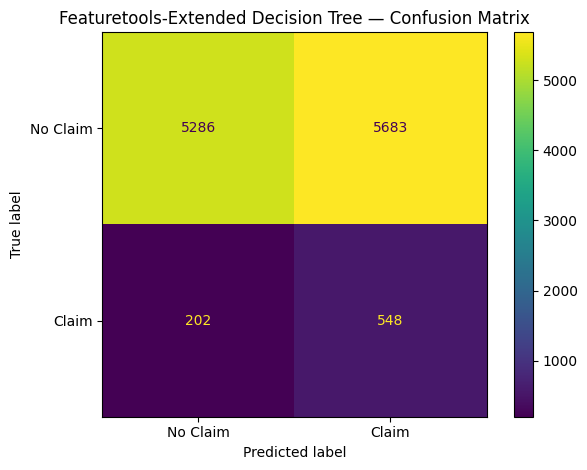

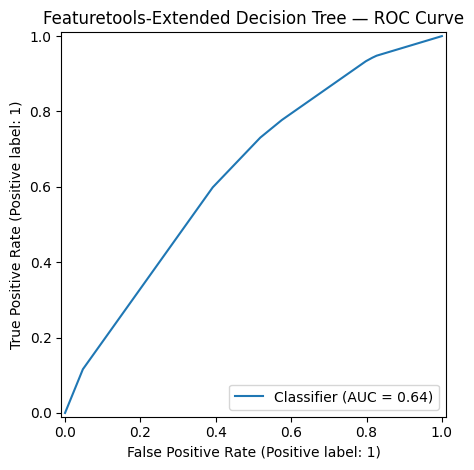

In [21]:

# Classification report
print("Selected model:", model_name)
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Claim", "Claim"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Claim", "Claim"]
)
plt.title(f"{model_name} — Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title(f"{model_name} — ROC Curve")
plt.tight_layout()
plt.show()



### Final Test Evaluation — Observations

The table and classification report above contain the current selected model's held-out test results.

Discuss:
- Test ROC-AUC and the model's ability to rank claim cases.
- Precision and recall, particularly given the imbalanced target.
- The confusion matrix and the number of actual claim cases identified.
- The likely trade-off between identifying more claims and creating unnecessary investigation work.

Do not copy metrics from earlier runs. Use the values generated by the current notebook execution.

The model is a candidate for further validation; these results do not establish business savings or production readiness.



#### 2.5. Experiment Tracking with MLflow

MLflow records the cross-validation and held-out test metrics for the Logistic Regression baseline and Featuretools-extended Decision Tree. The runs include model parameters and fitted pipeline artifacts.

The experiment comparison is exported to CSV for inspection outside the notebook.


In [22]:

# ============================================================
# MLflow tracking for both candidate models
# ============================================================

OUT_DIR = "model_artifacts"
os.makedirs(OUT_DIR, exist_ok=True)

tracking_db = os.path.abspath(
    os.path.join(OUT_DIR, "mlflow_automl.db")
)
mlflow.set_tracking_uri(f"sqlite:///{tracking_db}")
mlflow.set_experiment("SafeDrive_Claim_Prediction_AutoML")

model_runs = [
    (
        "Logistic Regression",
        logistic_model,
        X_test,
        logistic_cv
    ),
    (
        "Featuretools-Extended Decision Tree",
        automl_decision_tree_model,
        X_test2,
        automl_cv
    )
]
mlflow_run_ids = {}

for name, model, X_test_model, cv_result in model_runs:
    y_prob_model = model.predict_proba(X_test_model)[:, 1]
    y_pred_model = model.predict(X_test_model)

    with mlflow.start_run(run_name=name) as run:
        mlflow_run_ids[name] = run.info.run_id

        mlflow.log_param("model_name", name)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("random_state", RANDOM_STATE)

        if name == "Featuretools-Extended Decision Tree":
            mlflow.log_params(automl_study.best_params)
            mlflow.log_param(
                "featuretools_features_added",
                len(featuretools_features)
            )

        for metric in scoring:
            mlflow.log_metric(
                f"cv_{metric}_mean",
                float(cv_result[f"test_{metric}"].mean())
            )

        mlflow.log_metric(
            "test_roc_auc",
            float(roc_auc_score(y_test, y_prob_model))
        )
        mlflow.log_metric(
            "test_precision",
            float(precision_score(y_test, y_pred_model, zero_division=0))
        )
        mlflow.log_metric(
            "test_recall",
            float(recall_score(y_test, y_pred_model, zero_division=0))
        )
        mlflow.log_metric(
            "test_f1",
            float(f1_score(y_test, y_pred_model, zero_division=0))
        )
        mlflow.log_metric(
            "test_accuracy",
            float(accuracy_score(y_test, y_pred_model))
        )

        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model",
            serialization_format="pickle"
        )

experiment = mlflow.get_experiment_by_name(
    "SafeDrive_Claim_Prediction_AutoML"
)

experiment_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas"
)

experiment_log_path = os.path.join(
    OUT_DIR, "experiment_comparison_log_automl.csv"
)
experiment_runs.to_csv(experiment_log_path, index=False)

print("Logged model runs:", len(mlflow_run_ids))
print("Experiment log:", experiment_log_path)
display(experiment_runs.head())

2026/10/26 20:58:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 20:58:12 INFO mlflow.store.db.utils: Updating database tables
2026/10/26 20:58:14 INFO mlflow.tracking.fluent: Experiment with name 'SafeDrive_Claim_Prediction_AutoML' does not exist. Creating a new experiment.
2026/10/26 20:58:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 20:58:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 20:58:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 20:58:29 WARNING mlflow.sklearn: Saving scikit-learn models i

Logged model runs: 2
Experiment log: model_artifacts\experiment_comparison_log_automl.csv


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.cv_recall_mean,metrics.cv_precision_mean,...,params.min_samples_split,params.model_name,params.featuretools_features_added,params.cv_folds,params.random_state,params.min_samples_leaf,tags.mlflow.user,tags.mlflow.runName,tags.mlflow.source.type,tags.mlflow.source.name
0,165b4e0cfa1b40829284ed25e0df56e1,1,FINISHED,file:c:/Users/farheen/Downloads/SafeDrive_Caps...,2026-10-26 15:28:29.266000+00:00,2026-10-26 15:28:34.216000+00:00,0.636501,0.497824,0.683463,0.090878,...,44,Featuretools-Extended Decision Tree,2,5,42,19,farheen,Featuretools-Extended Decision Tree,NOTEBOOK,automl_model_comparison_and_versioning_FINAL.i...
1,f781a5af446949a9a652db5f5fe7fc4e,1,FINISHED,file:c:/Users/farheen/Downloads/SafeDrive_Caps...,2026-10-26 15:28:15.345000+00:00,2026-10-26 15:28:29.182000+00:00,0.610118,0.568735,0.599730,0.085922,...,None,Logistic Regression,None,5,42,None,farheen,Logistic Regression,NOTEBOOK,automl_model_comparison_and_versioning_FINAL.i...



#### 2.6. Model Versioning and Metadata
The metadata records the model version, MLflow run ID, training dataset, selected features, Featuretools features, evaluation metrics and approval status.


In [23]:
from datetime import datetime, timezone

OUT_DIR = "model_artifacts"
os.makedirs(OUT_DIR, exist_ok=True)

timestamp_utc = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
model_version = f"v1_automl_{timestamp_utc}"

MODEL_PATH = os.path.join(
    OUT_DIR, f"safedrive_model_{model_version}.joblib"
)
METADATA_PATH = os.path.join(
    OUT_DIR, f"safedrive_model_{model_version}_metadata.json"
)

joblib.dump(selected_model, MODEL_PATH)

selected_cv_row = comparison_results.loc[
    comparison_results["Model"] == model_name
].iloc[0]

metadata = {
    "project": "SafeDrive Insurance Claims",
    "model_name": model_name,
    "model_version": model_version,
    "mlflow_run_id": mlflow_run_ids[model_name],
    "training_dataset": DATA_PATH,
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "base_feature_columns": base_feature_cols,
    "extended_feature_columns": extended_feature_cols,
    "featuretools_features": featuretools_features,
    "selected_feature_columns": (
        base_feature_cols
        if model_name == "Logistic Regression"
        else extended_feature_cols
    ),
    "cv_metrics": {
        key: float(value)
        for key, value in selected_cv_row.items()
        if key != "Model" and pd.notna(value)
    },
    "test_metrics": {
        key: float(value)
        for key, value in final_results.iloc[0].items()
        if key != "Model" and pd.notna(value)
    },
    "approval_status": "Pending business review",
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Selected model:", model_name)
print("Model saved:", MODEL_PATH)
print("Metadata saved:", METADATA_PATH)


Selected model: Featuretools-Extended Decision Tree
Model saved: model_artifacts\safedrive_model_v1_automl_20261026T152834Z.joblib
Metadata saved: model_artifacts\safedrive_model_v1_automl_20261026T152834Z_metadata.json



#### 2.7. Data Quality and Drift Report Using Evidently

Compare the selected model's training and test predictor distributions using Evidently. The report should include data summary and drift information.

This is a train/test distribution check. It does not establish whether production data is drifting over time.


In [24]:
import evidently

print("Evidently version:", evidently.__version__)

Evidently version: 0.7.21


In [25]:
# ============================================================
# Generate and save the Evidently data quality / drift report
# ============================================================

from evidently import Report
from evidently.presets import DataSummaryPreset, DataDriftPreset

report = Report([
    DataSummaryPreset(),
    DataDriftPreset()
])

report_result = report.run(
    reference_data=X_train2,
    current_data=X_test2
)

evidently_path = os.path.join(OUT_DIR, "evidently_report_automl.html")
report_result.save_html(evidently_path)

assert os.path.exists(evidently_path), "Evidently HTML report was not saved."

print("Evidently report saved:", evidently_path)
print("File size (bytes):", os.path.getsize(evidently_path))

Evidently report saved: model_artifacts\evidently_report_automl.html
File size (bytes): 5605039



#### 2.8. SHAP Explainability

Use SHAP to explain the selected model using the same feature set used during training. The analysis produces a global feature-importance plot and a feature-level summary.

SHAP describes how features contribute to model predictions; it does not prove that a feature causes a claim.


In [26]:

# ============================================================
# Prepare the selected model's matching test data for SHAP
# ============================================================

import shap

X_shap_raw = (
    X_test.copy()
    if model_name == "Logistic Regression"
    else X_test2.copy()
)

fitted_preprocessor = selected_model.named_steps["preprocessor"]
fitted_classifier = selected_model.named_steps["model"]

X_shap_transformed = fitted_preprocessor.transform(X_shap_raw)

try:
    shap_feature_names = (
        fitted_preprocessor.get_feature_names_out().tolist()
    )
except Exception:
    shap_feature_names = [
        f"feature_{i}" for i in range(X_shap_transformed.shape[1])
    ]

sample_n = min(200, X_shap_transformed.shape[0])
sample_idx = np.random.RandomState(
    RANDOM_STATE
).choice(X_shap_transformed.shape[0], sample_n, replace=False)

X_shap_sample = X_shap_transformed[sample_idx]

if hasattr(X_shap_sample, "toarray"):
    X_shap_sample = X_shap_sample.toarray()

X_shap_sample = np.asarray(X_shap_sample)

print("SHAP sample shape:", X_shap_sample.shape)
print("Feature names:", len(shap_feature_names))


SHAP sample shape: (200, 99)
Feature names: 99


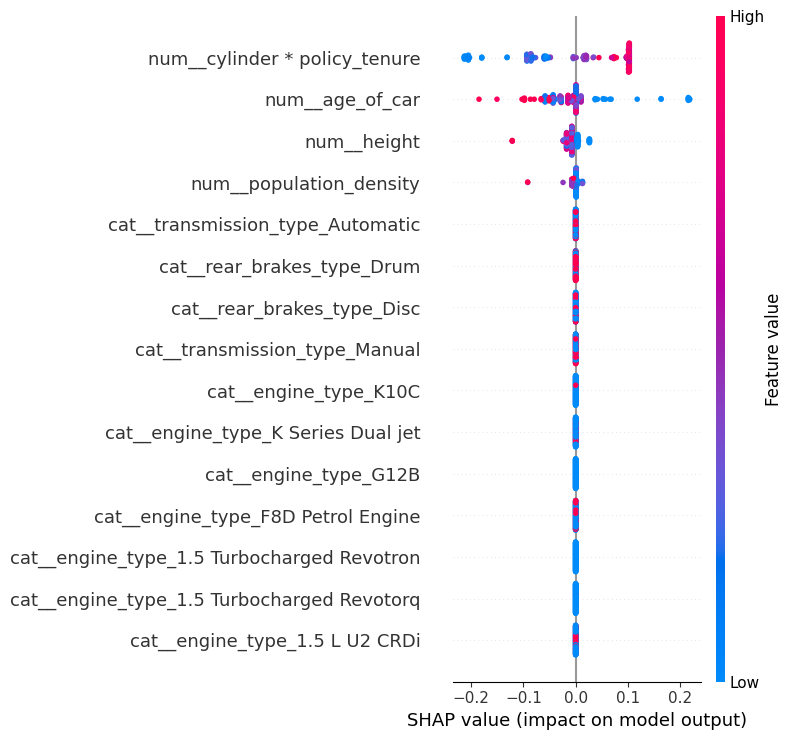

SHAP plot saved: model_artifacts\shap_summary_automl.png
SHAP CSV saved: model_artifacts\shap_feature_summary.csv
Featuretools features in top 10: ['num__cylinder * policy_tenure']


,feature,mean_abs_shap,mean_signed_shap,direction
0,num__cylinder * policy_tenure,0.095348,-0.014842,Negative contribution on average
1,num__age_of_car,0.035617,-0.005413,Negative contribution on average
2,num__height,0.011442,-0.006762,Negative contribution on average
3,num__population_density,0.003380,-0.000965,Negative contribution on average
4,num__age_of_policyholder,0.000000,0.000000,Approximately neutral
5,num__airbags,0.000000,0.000000,Approximately neutral
6,num__policy_tenure,0.000000,0.000000,Approximately neutral
7,num__is_adjustable_steering,0.000000,0.000000,Approximately neutral
8,num__is_tpms,0.000000,0.000000,Approximately neutral
9,num__is_parking_sensors,0.000000,0.000000,Approximately neutral


In [27]:

# ============================================================
# Calculate SHAP values, plot and export the feature summary
# ============================================================

if isinstance(fitted_classifier, DecisionTreeClassifier):
    explainer = shap.TreeExplainer(fitted_classifier)
    shap_raw = explainer.shap_values(X_shap_sample)
else:
    background = X_shap_transformed[:min(100, len(X_shap_transformed))]
    if hasattr(background, "toarray"):
        background = background.toarray()

    explainer = shap.KernelExplainer(
        lambda arr: fitted_classifier.predict_proba(arr)[:, 1],
        np.asarray(background)
    )
    shap_raw = explainer.shap_values(
        X_shap_sample, nsamples=100
    )

# Normalize binary-classification SHAP output formats.
if isinstance(shap_raw, list):
    shap_values_array = np.asarray(
        shap_raw[1] if len(shap_raw) > 1 else shap_raw[0]
    )
else:
    shap_values_array = np.asarray(shap_raw)
    if (
        shap_values_array.ndim == 3
        and shap_values_array.shape[-1] == 2
    ):
        shap_values_array = shap_values_array[:, :, 1]

assert shap_values_array.ndim == 2
assert shap_values_array.shape[1] == len(shap_feature_names)

# Save the summary plot.
shap_plot_path = os.path.join(OUT_DIR, "shap_summary_automl.png")

shap.summary_plot(
    shap_values_array,
    X_shap_sample,
    feature_names=shap_feature_names,
    max_display=15,
    show=False
)

plt.tight_layout()
plt.savefig(shap_plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Required SHAP feature summary CSV.
shap_feature_summary = pd.DataFrame({
    "feature": shap_feature_names,
    "mean_abs_shap": np.abs(shap_values_array).mean(axis=0),
    "mean_signed_shap": shap_values_array.mean(axis=0)
}).sort_values(
    "mean_abs_shap", ascending=False
).reset_index(drop=True)

shap_feature_summary["direction"] = np.select(
    [
        shap_feature_summary["mean_signed_shap"] > 0,
        shap_feature_summary["mean_signed_shap"] < 0
    ],
    [
        "Positive contribution on average",
        "Negative contribution on average"
    ],
    default="Approximately neutral"
)

shap_csv_path = os.path.join(
    OUT_DIR, "shap_feature_summary.csv"
)
shap_feature_summary.to_csv(shap_csv_path, index=False)

# Check whether any retained Featuretools feature appears in top 10.
def is_featuretools_feature(shap_name, feature_name):
    cleaned = shap_name.split("__", 1)[-1]
    return (
        cleaned == feature_name
        or cleaned.startswith(feature_name + "_")
    )

top10_features = shap_feature_summary.head(10)["feature"].tolist()

featuretools_top10 = [
    name for name in top10_features
    if any(
        is_featuretools_feature(name, ft_name)
        for ft_name in featuretools_features
    )
]

print("SHAP plot saved:", shap_plot_path)
print("SHAP CSV saved:", shap_csv_path)
print("Featuretools features in top 10:", featuretools_top10)

display(shap_feature_summary.head(15))



#### 2.9. Generate Final Predictions and Risk Bands

Generate predicted claim probabilities and predicted classes for the held-out test policies using the selected model. Assign Low, Medium, High and Very High risk bands using the 40th, 75th and 90th percentiles of predicted claim probabilities.

Export the predictions to `prediction_output.csv` and compare actual claim rates across risk bands. Only policies scored by the model should receive a model-generated risk level.


Raw probability thresholds:
40th percentile: 0.3752
75th percentile: 0.5968
90th percentile: 0.5968

Prediction file saved: model_artifacts\prediction_output.csv


,risk_level,policies,actual_claims,actual_claim_rate,mean_claim_probability
0,Low,4826,167,0.034604,0.317442
1,Medium,2145,134,0.062471,0.501161
2,High,4142,362,0.087397,0.596845
3,Very High,606,87,0.143564,0.685869



Actual claim rates increase across risk bands: True


<Figure size 900x500 with 0 Axes>

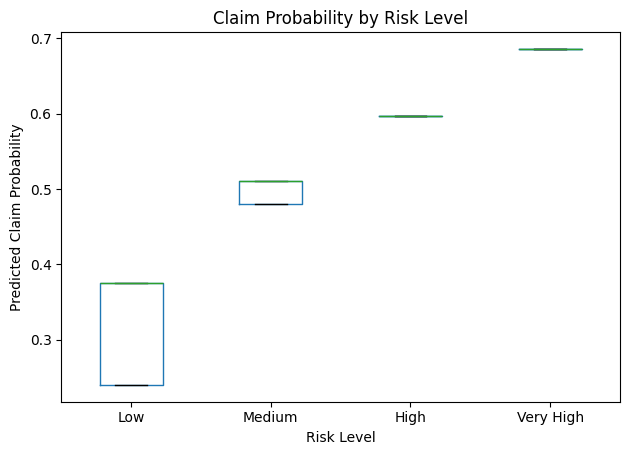

Risk plot saved: model_artifacts\claim_probability_by_risk_level.png

Final prediction columns: ['policy_id', 'actual_outcome', 'predicted_class', 'claim_probability', 'risk_level']

Risk-level counts:
risk_level
Low          4826
Medium       2145
High         4142
Very High     606
Name: count, dtype: int64


In [28]:
# ============================================================
# Final Prediction Export and Risk Analysis
# ============================================================

# 1. Create the prediction dataset for the held-out test policies.
prediction_output = pd.DataFrame({
    "policy_id": df.loc[X_selected_test.index, "policy_id"].values,
    "actual_outcome": y_test.loc[X_selected_test.index].values,
    "predicted_class": y_pred,
    "claim_probability": y_prob
})

# 2. Calculate the 40th, 75th and 90th percentile probability thresholds.
q40, q75, q90 = prediction_output["claim_probability"].quantile(
    [0.40, 0.75, 0.90]
)

print("Raw probability thresholds:")
print("40th percentile:", round(q40, 4))
print("75th percentile:", round(q75, 4))
print("90th percentile:", round(q90, 4))

# 3. Assign percentile-based risk bands.
# Decision Trees often give the same probability to many policies.
# Ranking handles ties so all four bands can be represented. This is
# rank-based segmentation, not classification using the raw cut-off values.
probability_percentile = prediction_output["claim_probability"].rank(
    method="average",
    pct=True
)

prediction_output["risk_level"] = np.select(
    [
        probability_percentile <= 0.40,
        probability_percentile <= 0.75,
        probability_percentile <= 0.90
    ],
    ["Low", "Medium", "High"],
    default="Very High"
)

risk_order = ["Low", "Medium", "High", "Very High"]
prediction_output["risk_level"] = pd.Categorical(
    prediction_output["risk_level"],
    categories=risk_order,
    ordered=True
)

# 4. Validate the prediction data.
assert prediction_output["policy_id"].is_unique, "Duplicate policy IDs found."
assert prediction_output["claim_probability"].notna().all(), "Missing probabilities found."
assert prediction_output["claim_probability"].between(0, 1).all(), "Probabilities must be between 0 and 1."
assert prediction_output["actual_outcome"].notna().all(), "Missing actual outcomes found."

# 5. Export predictions.
prediction_path = os.path.join(OUT_DIR, "prediction_output.csv")
prediction_output.to_csv(prediction_path, index=False)
print("\nPrediction file saved:", prediction_path)

# 6. Summarise policies and actual claims by risk band.
risk_summary = (
    prediction_output
    .groupby("risk_level", observed=False)
    .agg(
        policies=("policy_id", "count"),
        actual_claims=("actual_outcome", "sum"),
        actual_claim_rate=("actual_outcome", "mean"),
        mean_claim_probability=("claim_probability", "mean")
    )
    .reindex(risk_order)
    .reset_index()
)
display(risk_summary)

# 7. Check whether observed claim rates increase across risk bands.
claim_rates = risk_summary["actual_claim_rate"].dropna().tolist()
claim_rates_monotonic = all(
    claim_rates[i] <= claim_rates[i + 1]
    for i in range(len(claim_rates) - 1)
)
print("\nActual claim rates increase across risk bands:", claim_rates_monotonic)
if not claim_rates_monotonic:
    print("Review the segment results; do not alter observed outcomes to force monotonicity.")

# 8. Plot predicted probabilities by risk band.
plt.figure(figsize=(9, 5))
prediction_output.boxplot(
    column="claim_probability",
    by="risk_level",
    grid=False
)
plt.title("Claim Probability by Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Predicted Claim Probability")
plt.tight_layout()

risk_plot_path = os.path.join(OUT_DIR, "claim_probability_by_risk_level.png")
plt.savefig(risk_plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()
print("Risk plot saved:", risk_plot_path)

# 9. Confirm final schema and band counts.
print("\nFinal prediction columns:", prediction_output.columns.tolist())
print("\nRisk-level counts:")
print(prediction_output["risk_level"].value_counts(sort=False))


#### 2.10. Calculate Business KPIs and Prepare the Final Dataset

Calculate the required policy and claim KPIs and merge the held-out test predictions onto the full dataset using `policy_id`.

Policies outside the scored test set must remain unscored. Do not treat a missing prediction as a low-risk policy or as a model prediction.


In [29]:

# ============================================================
# Final KPI calculations and Power BI export package
# ============================================================

from pathlib import Path

OUT_DIR = "model_artifacts"
POWERBI_DIR = os.path.join(OUT_DIR, "powerbi_exports")
os.makedirs(POWERBI_DIR, exist_ok=True)

TARGET = "is_claim"
ID_COL = "policy_id"

# 1. Full policy-level data: predictions exist only for scored test rows.
scored_dataset = df.merge(
    prediction_output[
        [
            "policy_id",
            "predicted_class",
            "claim_probability",
            "risk_level"
        ]
    ],
    on=ID_COL,
    how="left",
    validate="one_to_one"
)

# 2. Core portfolio KPIs from the complete source dataset.
total_policies = int(df[ID_COL].nunique())
total_claims = int(pd.to_numeric(df[TARGET], errors="coerce").sum())
overall_claim_rate_pct = (
    total_claims / total_policies * 100
    if total_policies else np.nan
)

# High + Very High count is explicitly for scored policies only.
high_very_high_count = int(
    prediction_output["risk_level"]
    .astype(str)
    .isin(["High", "Very High"])
    .sum()
)

ncap_candidates = [
    col for col in df.columns
    if col.lower() in {"ncap", "ncap_rating"}
]

if ncap_candidates:
    ncap_col = ncap_candidates[0]
    average_ncap = pd.to_numeric(
        df[ncap_col], errors="coerce"
    ).mean()
else:
    average_ncap = np.nan
    print("WARNING: No NCAP rating field found in the dataset.")

kpi_summary = pd.DataFrame([
    {"KPI": "Total Policies", "Value": total_policies},
    {"KPI": "Total Claims", "Value": total_claims},
    {"KPI": "Overall Claim Rate (%)", "Value": overall_claim_rate_pct},
    {
        "KPI": "High + Very High Risk Policies (Scored Test Set)",
        "Value": high_very_high_count
    },
    {"KPI": "Average NCAP Rating", "Value": average_ncap}
])

# 3. Risk-band summary for the model-scored policies.
risk_summary = (
    prediction_output
    .groupby("risk_level", observed=False)
    .agg(
        policies=("policy_id", "count"),
        actual_claims=("actual_outcome", "sum"),
        actual_claim_rate=("actual_outcome", "mean"),
        mean_claim_probability=("claim_probability", "mean")
    )
    .reindex(["Low", "Medium", "High", "Very High"])
    .reset_index()
)

# 4. Cross-validation comparison, model metrics and SHAP summary.
# Save CSVs into one predictable folder for Power BI.
powerbi_files = {
    "PowerBI_PolicyPortfolio.csv": df,
    "PowerBI_ModelPredictions.csv": prediction_output,
    "PowerBI_RiskSummary.csv": risk_summary,
    "PowerBI_ModelComparison.csv": comparison_results,
    "PowerBI_FinalTestMetrics.csv": final_results,
    "PowerBI_KPIs.csv": kpi_summary,
    "PowerBI_SHAPFeatureSummary.csv": shap_feature_summary
}

for filename, data in powerbi_files.items():
    data.to_csv(
        os.path.join(POWERBI_DIR, filename),
        index=False
    )

# Save the scored dataset separately: rows without predictions stay unscored.
scored_dataset.to_csv(
    os.path.join(POWERBI_DIR, "PowerBI_ScoredPolicyDataset.csv"),
    index=False
)

# Keep standard Stage 3 outputs as well.
kpi_summary.to_csv(
    os.path.join(OUT_DIR, "business_kpi_summary.csv"),
    index=False
)
scored_dataset.to_csv(
    os.path.join(OUT_DIR, "full_dataset_with_test_predictions.csv"),
    index=False
)
risk_summary.to_csv(
    os.path.join(OUT_DIR, "risk_band_summary.csv"),
    index=False
)

# 5. Data-integrity checks before the dashboard handoff.
assert df[ID_COL].is_unique, "Source policy_id must be unique."
assert prediction_output[ID_COL].is_unique, (
    "Prediction policy_id must be unique."
)
assert len(prediction_output) == len(X_test), (
    "Prediction row count does not match the held-out test set."
)
assert scored_dataset[ID_COL].is_unique, (
    "Merge produced duplicate policy rows."
)
assert scored_dataset["claim_probability"].notna().sum() == len(
    prediction_output
), "Merged prediction count does not match the prediction export."

print("Power BI export folder:", POWERBI_DIR)
print("\nExported files:")
for filename in sorted(os.listdir(POWERBI_DIR)):
    print("-", filename)

print("\nKPI summary:")
display(kpi_summary)

print("\nRisk-band summary:")
display(risk_summary)

print(
    "\nFull policies:", len(df),
    "| Scored test policies:", len(prediction_output),
    "| Unscored policies:", len(df) - len(prediction_output)
)


Power BI export folder: model_artifacts\powerbi_exports

Exported files:
- PowerBI_FinalTestMetrics.csv
- PowerBI_KPIs.csv
- PowerBI_ModelComparison.csv
- PowerBI_ModelPredictions.csv
- PowerBI_PolicyPortfolio.csv
- PowerBI_RiskSummary.csv
- PowerBI_SHAPFeatureSummary.csv
- PowerBI_ScoredPolicyDataset.csv

KPI summary:


,KPI,Value
0,Total Policies,58592.000000
1,Total Claims,3748.000000
2,Overall Claim Rate (%),6.396778
3,High + Very High Risk Policies (Scored Test Set),4748.000000
4,Average NCAP Rating,1.759950



Risk-band summary:


,risk_level,policies,actual_claims,actual_claim_rate,mean_claim_probability
0,Low,4826,167,0.034604,0.317442
1,Medium,2145,134,0.062471,0.501161
2,High,4142,362,0.087397,0.596845
3,Very High,606,87,0.143564,0.685869



Full policies: 58592 | Scored test policies: 11719 | Unscored policies: 46873



#### Stage 3 Summary: AutoML, Model Governance and Risk Segmentation

### Feature Engineering and Model Comparison
- Featuretools Deep Feature Synthesis generated candidate numeric features.
- DFS candidates were screened against the strongest base numeric-feature correlation.
- Logistic Regression and the Optuna-tuned Featuretools-extended Decision Tree were compared using five-fold stratified cross-validation.
- The selected model was evaluated on the held-out test set.

### Experiment Tracking and Versioning
MLflow logs candidate-model parameters and metrics. The selected model and structured metadata are saved with an AutoML-specific version identifier.

### Data Quality and Explainability
Evidently provides a train/test data-summary and drift report. SHAP provides a global feature-importance plot and a feature-level summary CSV.

### Prediction and Business Outputs
The notebook exports test predictions, quantile-based risk bands, risk-band summaries, a probability box plot, a business KPI summary and a full dataset with test predictions merged by policy ID.

### Limitations
- The target is imbalanced, so precision, recall, F1 and ROC-AUC must be interpreted together.
- The test-set risk bands are relative to the scored sample and do not constitute calibrated business risk thresholds.
- SHAP describes model behaviour, not causation.
- Train/test distribution comparison is not production drift monitoring.
- Model approval requires further validation and business review.

The model should be treated as a candidate for further validation, not automatically approved for operational use.


In [30]:

# ============================================================
# Save the Power BI DAX measure reference
# ============================================================

dax_reference = r"""
SAFEDRIVE INSURANCE CLAIMS — POWER BI DAX MEASURES
=================================================

Create each item below using Modeling > New measure.

Total Policies =
DISTINCTCOUNT ( PowerBI_PolicyPortfolio[policy_id] )

Total Claims =
SUM ( PowerBI_PolicyPortfolio[is_claim] )

Overall Claim Rate =
DIVIDE ( [Total Claims], [Total Policies], 0 )

Scored Policies =
DISTINCTCOUNT ( PowerBI_ModelPredictions[policy_id] )

Predicted Claim Policies =
CALCULATE (
    DISTINCTCOUNT ( PowerBI_ModelPredictions[policy_id] ),
    PowerBI_ModelPredictions[predicted_class] = 1
)

Average Claim Probability =
AVERAGE ( PowerBI_ModelPredictions[claim_probability] )

High Risk Policies =
CALCULATE (
    DISTINCTCOUNT ( PowerBI_ModelPredictions[policy_id] ),
    PowerBI_ModelPredictions[risk_level] IN { "High", "Very High" }
)

High Risk Share =
DIVIDE ( [High Risk Policies], [Scored Policies], 0 )

Actual Claims in Scored Set =
SUM ( PowerBI_ModelPredictions[actual_outcome] )

Claim Rate in Scored Set =
DIVIDE (
    [Actual Claims in Scored Set],
    [Scored Policies],
    0
)

Average NCAP Rating =
AVERAGE ( PowerBI_PolicyPortfolio[ncap_rating] )

Policies by Risk Level =
DISTINCTCOUNT ( PowerBI_ModelPredictions[policy_id] )

Actual Claim Rate by Risk Level =
DIVIDE (
    SUM ( PowerBI_ModelPredictions[actual_outcome] ),
    DISTINCTCOUNT ( PowerBI_ModelPredictions[policy_id] ),
    0
)

Best CV ROC-AUC =
MAX ( PowerBI_ModelComparison[ROC_AUC] )

Best CV F1 Score =
MAX ( PowerBI_ModelComparison[F1_Score] )


FORMATTING
-----------
- Overall Claim Rate: Percentage
- Average Claim Probability: Percentage
- High Risk Share: Percentage
- Claim Rate in Scored Set: Percentage
- Actual Claim Rate by Risk Level: Percentage
- Average NCAP Rating: Decimal number


DATA TYPES
----------
- policy_id: same data type in both policy and prediction tables
- is_claim: Whole Number (0/1)
- actual_outcome: Whole Number (0/1)
- predicted_class: Whole Number (0/1)
- claim_probability: Decimal Number
- risk_level: Text
- ncap_rating: numeric, if present


RELATIONSHIP
------------
PowerBI_PolicyPortfolio[policy_id] (one)
    -> PowerBI_ModelPredictions[policy_id] (many)

Use single-direction filtering from PolicyPortfolio to ModelPredictions.
Confirm policy_id is unique in the portfolio table.
"""

dax_path = os.path.join(
    POWERBI_DIR, "SafeDrive_PowerBI_DAX_Measures.txt"
)

with open(dax_path, "w", encoding="utf-8") as f:
    f.write(dax_reference.strip() + "\n")

print("DAX reference saved:", dax_path)


DAX reference saved: model_artifacts\powerbi_exports\SafeDrive_PowerBI_DAX_Measures.txt
